# Task 2: Predictive modelling of customer bookings

*Forage job simulation (British Airways data science programme). A learning exercise, not client work; not reviewed by British Airways.*

**Question.** From the details of a booking enquiry, how well can we predict whether the customer completes the booking, and which variables carry the signal?

**Data.** `customer_booking.csv` from the simulation. It is not included in the repository.

# **Upload and inspect the dataset**

In [1]:
import pandas as pd

try:  # Google Colab: upload the file when prompted
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
except ImportError:  # running locally: put the file in data/customer_booking.csv
    file_name = "data/customer_booking.csv"

df = pd.read_csv(file_name, encoding="ISO-8859-1")

print("Dataset shape:", df.shape)
df.head()

Saving customer_booking.csv to customer_booking.csv
Dataset shape: (50000, 14)


In [2]:
print("Share of enquiries by outcome:")
print(df["booking_complete"].value_counts(normalize=True).rename("share").round(4))

Share of enquiries by outcome:
booking_complete
0    0.8504
1    0.1496
Name: share, dtype: float64


## Explore before modelling

Accuracy is misleading because a model that predicts “no booking” for every enquiry would still achieve 85.04% accuracy, despite failing to identify a single customer who actually completes a booking. We should also evaluate precision, recall, ROC-AUC and PR-AUC to understand how well the model identifies likely bookings and how reliable those predictions are.

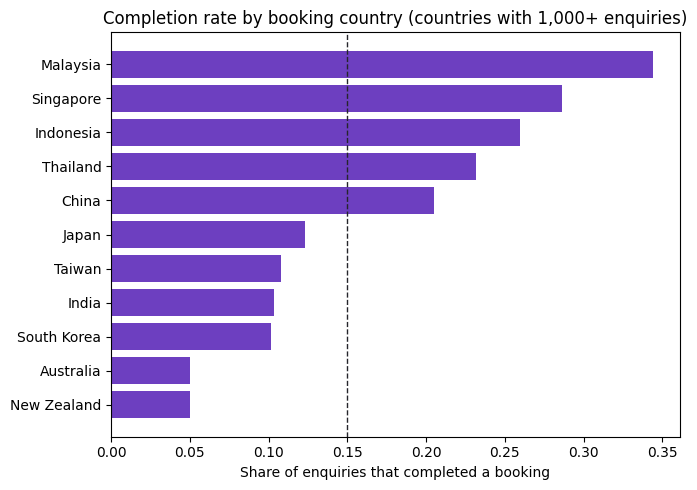

,completion_rate,rows
booking_origin,,
Australia,0.050,17872
Malaysia,0.344,7174
South Korea,0.101,4559
Japan,0.123,3885
China,0.205,3387
Indonesia,0.260,2369
Taiwan,0.108,2077
Thailand,0.232,2030
India,0.103,1270


In [3]:
import matplotlib.pyplot as plt

origin = df.groupby("booking_origin")["booking_complete"].agg(completion_rate="mean", rows="size")
top = origin[origin["rows"] >= 1000].sort_values("completion_rate")

plt.figure(figsize=(7, 5))
plt.barh(top.index, top["completion_rate"], color="#6d3fc0")
plt.axvline(df["booking_complete"].mean(), color="#25252b", ls="--", lw=1)
plt.xlabel("Share of enquiries that completed a booking")
plt.title("Completion rate by booking country (countries with 1,000+ enquiries)")
plt.tight_layout()
plt.show()
top.sort_values("rows", ascending=False).round(3)

**Key insight**:

Malaysia has the highest completion rate at 34.4%, while Australia and New Zealand have the lowest at 5.0%. Australia also has the largest sample, with 17,872 rows.
This suggests substantial differences in booking completion by origin. However, origin alone does not establish the cause; passenger characteristics, booking lead time, route, and sales channel may also matter.

# **Prepare the data and train the model**

In [4]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score
)

# Check the target
TARGET = "booking_complete"
assert TARGET in df.columns, f"Missing column: {TARGET}"
assert df[TARGET].isin([0, 1]).all(), "Target must contain only 0 and 1"

y = df[TARGET].astype(int)
X = df.drop(columns=[TARGET]).copy()

# Feature engineering
days = {"Mon": 1, "Tue": 2, "Wed": 3, "Thu": 4,
        "Fri": 5, "Sat": 6, "Sun": 7}

X["flight_day"] = X["flight_day"].map(days)
X["is_weekend_flight"] = X["flight_day"].isin([6, 7]).astype(int)

extras = [
    "wants_extra_baggage",
    "wants_preferred_seat",
    "wants_in_flight_meals"
]
X["n_extras_requested"] = X[extras].sum(axis=1)




In [5]:
# Retain the 15 most common origins; group the rest
top_origins = X["booking_origin"].value_counts().head(15).index
X["booking_origin"] = X["booking_origin"].where(
    X["booking_origin"].isin(top_origins), "Other"
)

# Exclude route: many routes have few observations
X = X.drop(columns=["route"])

# Convert categorical variables into model-readable columns
X = pd.get_dummies(
    X,
    columns=["sales_channel", "trip_type", "booking_origin"],
    dtype=int
)

print("Features:", X.shape[1])
print("Booking completion rate:", round(y.mean() * 100, 2), "%")

Features: 32
Booking completion rate: 14.96 %


# **Evaluate the model using five-fold cross-validation**

In [6]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

oof = np.zeros(len(y))
fold_results = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_test)[:, 1]
    oof[test_idx] = probabilities

    fold_results.append({
        "fold": fold,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

fold_results = pd.DataFrame(fold_results)
display(fold_results.round(4))

print("Mean ROC-AUC:", round(fold_results["ROC-AUC"].mean(), 4))
print("ROC-AUC standard deviation:", round(fold_results["ROC-AUC"].std(), 4))
print("Pooled out-of-fold ROC-AUC:", round(roc_auc_score(y, oof), 4))
print("Pooled out-of-fold PR-AUC:", round(average_precision_score(y, oof), 4))


,fold,ROC-AUC,PR-AUC
0,1,0.7582,0.3498
1,2,0.7673,0.3526
2,3,0.7699,0.3690
3,4,0.7661,0.3561
4,5,0.7672,0.3589


Mean ROC-AUC: 0.7657
ROC-AUC standard deviation: 0.0044
Pooled out-of-fold ROC-AUC: 0.7656
Pooled out-of-fold PR-AUC: 0.3566


A ROC-AUC of 0.766 is reasonably good because the model can distinguish between completed and non-completed bookings better than random guessing. It has a 76.6% chance of ranking a randomly selected completed booking higher than a randomly selected non-completed booking. The PR-AUC of 0.357 is also encouraging because it is higher than the baseline booking completion rate of 0.150, which matters when completed bookings are the minority class. The similar scores across all five folds suggest that the model's ranking performance is consistent across the validation splits.

However, the model is not perfect and will still make mistakes. It can help identify bookings that are more or less likely to be completed, allowing the business to target interventions such as reminders or follow-up messages. It cannot guarantee that a booking will be completed, establish that a particular factor causes completion, or determine which intervention will work without further testing. Before using it in practice, I would evaluate precision, recall, probability calibration, and the business costs of false predictions, then test whether targeted interventions actually improve completion rates.

# **Compare decision thresholds**

In [7]:

rows = []

for threshold in [0.50, 0.40, 0.30, 0.25, 0.20]:
    predicted = (oof >= threshold).astype(int)

    rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y, predicted),
        "precision": precision_score(y, predicted, zero_division=0),
        "recall": recall_score(y, predicted, zero_division=0),
        "F1": f1_score(y, predicted, zero_division=0),
        "share_flagged": predicted.mean()
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results.round(3))


,threshold,accuracy,precision,recall,F1,share_flagged
0,0.50,0.770,0.335,0.549,0.416,0.245
1,0.40,0.699,0.292,0.708,0.413,0.363
2,0.30,0.600,0.249,0.831,0.383,0.499
3,0.25,0.538,0.228,0.875,0.362,0.574
4,0.20,0.465,0.208,0.915,0.339,0.659


At a threshold of 0.5, the model correctly identifies about 33.5% of the bookings it flags as likely to complete. I would tell the manager that the model can help prioritise follow-up by ranking bookings according to their predicted likelihood of completion, but it should not be used as the only basis for decisions. Since the model misses about 45.1% of actual completed bookings at this threshold, lowering the threshold could help capture more bookings, although it would increase the number of enquiries requiring follow-up.

I would recommend choosing the threshold based on the team's follow-up capacity and the cost of intervention, then testing whether targeted follow-up improves actual booking completion rates.

# **Identify the most important variables**

,variable,importance,sd_across_folds
13,booking_origin,0.1896,0.0050
8,flight_duration,0.0230,0.0033
2,length_of_stay,0.0203,0.0027
11,sales_channel,0.0128,0.0018
1,purchase_lead,0.0097,0.0021
5,wants_extra_baggage,0.0040,0.0006
10,n_extras_requested,0.0035,0.0005
3,flight_hour,0.0022,0.0011
0,num_passengers,0.0016,0.0003
6,wants_preferred_seat,0.0016,0.0004


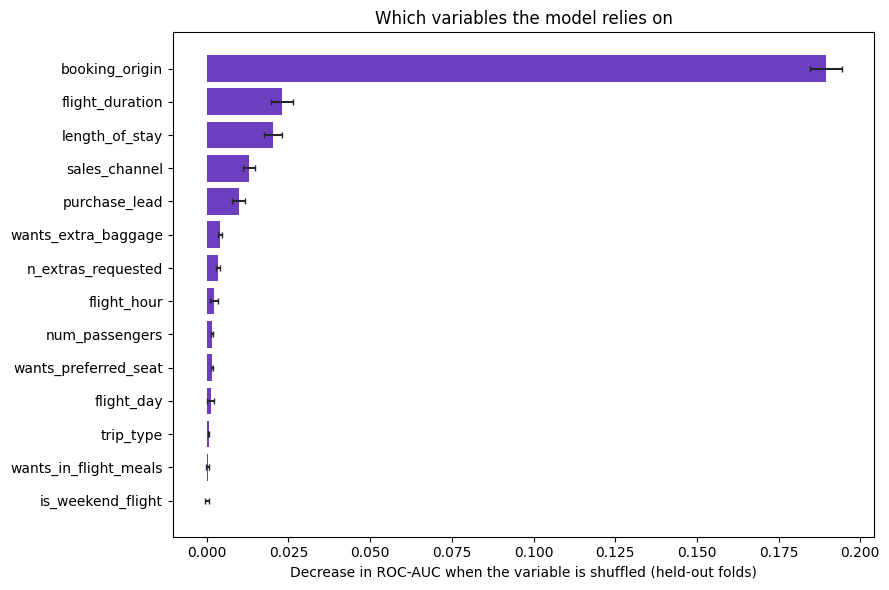

In [8]:
# Permutation importance on HELD-OUT folds, with all columns of one original variable shuffled together
groups = {}
for col in X.columns:
    base_name = next((p for p in ("sales_channel", "trip_type", "booking_origin") if col.startswith(p + "_")), col)
    groups.setdefault(base_name, []).append(col)

rng = np.random.default_rng(42)
N_REPEATS = 2
perm_rows = []

for train_idx, test_idx in cv.split(X, y):
    m = RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
        random_state=42, n_jobs=-1
    ).fit(X.iloc[train_idx], y.iloc[train_idx])

    X_te, y_te = X.iloc[test_idx], y.iloc[test_idx]
    base_auc = roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])

    row = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(N_REPEATS):
            X_shuffled = X_te.copy()
            X_shuffled[cols] = X_shuffled[cols].to_numpy()[rng.permutation(len(X_shuffled))]
            drops.append(base_auc - roc_auc_score(y_te, m.predict_proba(X_shuffled)[:, 1]))
        row[name] = np.mean(drops)
    perm_rows.append(row)

perm = pd.DataFrame(perm_rows)
importance_df = pd.DataFrame({
    "variable": perm.columns,
    "importance": perm.mean().values,
    "sd_across_folds": perm.std().values,
}).sort_values("importance", ascending=False)

display(importance_df.round(4))

plot_df = importance_df.sort_values("importance")
plt.figure(figsize=(9, 6))
plt.barh(plot_df["variable"], plot_df["importance"], xerr=plot_df["sd_across_folds"],
         color="#6d3fc0", ecolor="#25252b", capsize=2)
plt.xlabel("Decrease in ROC-AUC when the variable is shuffled (held-out folds)")
plt.title("Which variables the model relies on")
plt.tight_layout()
plt.show()

**Why the importance method changed.** In my first version of this cell I fitted the model on all the data and measured importance on that same data. A random forest can memorise the rows it trained on, so shuffling almost any column hurts it, including columns that carry no real signal. That version made `flight_day` (0.045), `wants_in_flight_meals` (0.025) and `is_weekend_flight` (0.016) look important, and it split booking country across 16 separate columns, so no single country looked dominant.

The method above fixes both problems: it shuffles on held-out folds the model has not seen, and it shuffles all columns that came from one original variable together (all the country columns count as one variable).

1. **Booking origin** dominates the feature importance results, with an importance score of 0.1896, compared with 0.0230 for flight duration, the second most important variable. Booking origin is approximately 8.2 times more important than flight duration, suggesting that where a booking originates provides the strongest predictive signal for completion.

2. The improved method gives a more reliable estimate because it measures importance on held-out data and groups related country columns into one original variable. This helps reveal the overall contribution of booking origin rather than spreading it across separate country indicators.

3. Variables such as `is_weekend_flight`, `wants_in_flight_meals`, `trip_type`, and `flight_day` contribute very little to predictive performance under this importance measure. Their near-zero importance suggests that removing them might simplify the model, although I would test their removal through cross-validation before deciding to exclude them.

## Robustness checks

**Check 1: remove booking country.** If the rest of the data predicts almost as well, the country story is weaker than it looks. **Check 2: remove duplicate rows.** If the result barely moves, the duplicates are not driving it.

In [9]:
def quick_auc(X_, y_):
    p = np.zeros(len(y_))
    for tr, te in cv.split(X_, y_):
        m = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                   random_state=42, n_jobs=-1).fit(X_.iloc[tr], y_.iloc[tr])
        p[te] = m.predict_proba(X_.iloc[te])[:, 1]
    return roc_auc_score(y_, p)

no_origin = X.drop(columns=groups["booking_origin"])
not_dupe = ~df.duplicated().values

print(f"Exact duplicate rows in the data: {int(df.duplicated().sum())}")
print(f"ROC-AUC, all features:          {roc_auc_score(y, oof):.3f}")
print(f"ROC-AUC, without booking_origin: {quick_auc(no_origin, y):.3f}")
print(f"ROC-AUC, duplicates removed:     {quick_auc(X[not_dupe], y[not_dupe]):.3f}")

Exact duplicate rows in the data: 719
ROC-AUC, all features:          0.766
ROC-AUC, without booking_origin: 0.679
ROC-AUC, duplicates removed:     0.762


The results show that `booking_origin` has a substantial influence on the model's predictive performance. Removing it reduces ROC-AUC from 0.766 to 0.679, a decrease of 0.087. This suggests that booking origin provides important information for distinguishing between completed and non-completed bookings.

Removing the 719 exact duplicate rows reduces ROC-AUC only slightly, from 0.766 to 0.762. This suggests that exact duplicates have a limited effect on overall model performance, although they should still be investigated to determine whether they represent legitimate repeated bookings or data-quality issues.

Overall, booking origin is an important predictor, while removing exact duplicates has little impact on ROC-AUC. However, I would also check whether duplicate records appear across training and validation folds and evaluate performance on later bookings before deploying the model.

# **Add a business summary**

In [10]:

baseline_accuracy = max(y.mean(), 1 - y.mean())

print(f"Total enquiries: {len(df):,}")
print(f"Completed-booking rate: {y.mean():.1%}")
print(f"Majority-class baseline accuracy: {baseline_accuracy:.1%}")
print(f"Cross-validation mean ROC-AUC: {fold_results['ROC-AUC'].mean():.3f}")
print(f"Cross-validation mean PR-AUC: {fold_results['PR-AUC'].mean():.3f}")


Total enquiries: 50,000
Completed-booking rate: 15.0%
Majority-class baseline accuracy: 85.0%
Cross-validation mean ROC-AUC: 0.766
Cross-validation mean PR-AUC: 0.357


The dataset contains 50,000 booking enquiries, of which approximately 15.0% result in completed bookings. A majority-class baseline would achieve 85.0% accuracy simply by predicting that every enquiry will not result in a completed booking. Therefore, accuracy alone is not a suitable measure of the model's performance.

The model achieves a mean cross-validation ROC-AUC of 0.766, indicating that it can distinguish between completed and non-completed bookings reasonably well. Its mean PR-AUC of 0.357 is also encouraging because it is substantially higher than the positive-class prevalence of 0.150. These results suggest that the model learns useful predictive patterns despite the imbalance in the dataset.

However, these metrics do not establish whether the model will improve business outcomes. The next step is to identify a practical decision threshold, evaluate the follow-up workload, and test whether targeted interventions increase booking completion rates.

## Summary for the One-Slide

1. **The data:** The dataset contains 50,000 booking enquiries, with only 15.0% resulting in completed bookings. This class imbalance means accuracy alone can be misleading, since predicting no completion for every enquiry would achieve 85.0% accuracy.

2. **How well the model works:** The model achieves a mean ROC-AUC of 0.766 and PR-AUC of 0.357, indicating useful predictive ability above random ranking and the positive-class baseline. However, at a 0.5 threshold, precision is only 33.5%, meaning approximately one in three flagged enquiries completes.

3. **What drives it, and what to do next:** Booking origin is the strongest predictor, and removing it reduces ROC-AUC from 0.766 to 0.679. Next, test the model on a later time period, explore additional route and customer-history features, and investigate why completion rates differ by origin before designing targeted interventions.

### Limitations

- The model ranks enquiries by predicted completion likelihood but is not reliable enough to make individual decisions without further validation.
- Random cross-validation does not establish how well the model will perform on future bookings.
- Booking origin is predictive, but the model does not establish why the differences exist or whether origin causes completion.
- This is a simulation exercise using a supplied dataset, not evidence of improved results in a live business setting.